Plot saved successfully as 'accuracy_vs_test_size.png'.


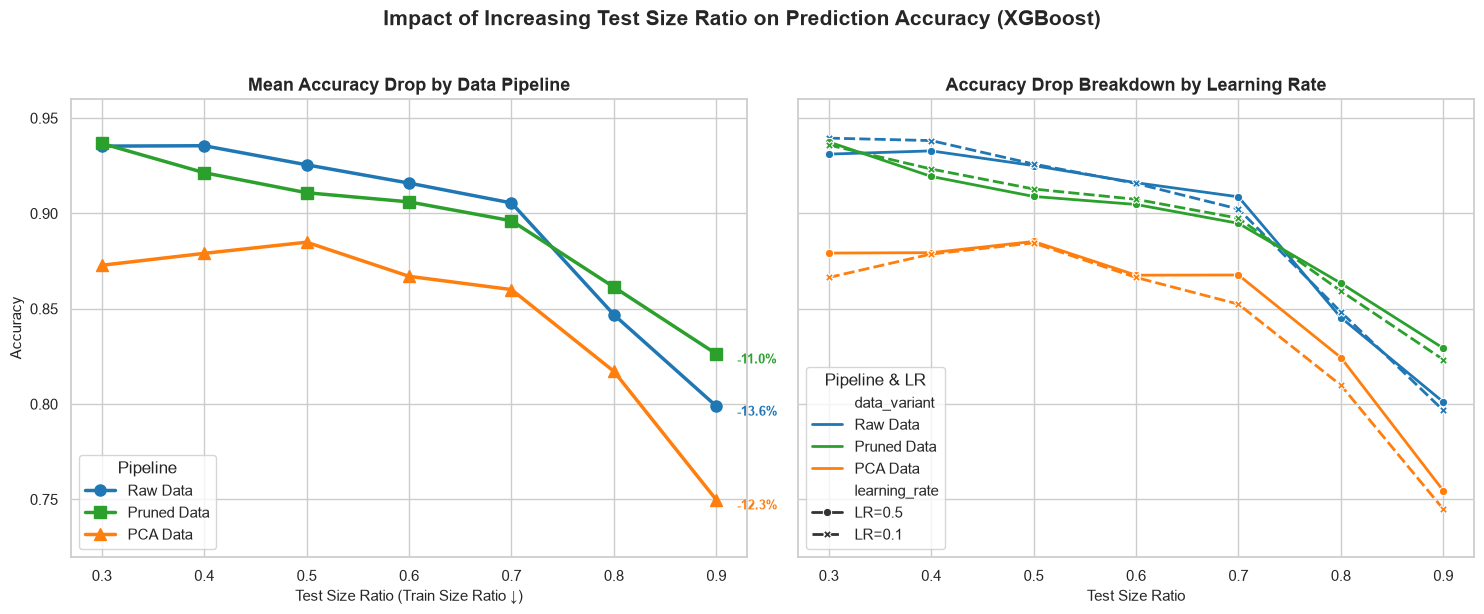

In [2]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def load_and_process_results(json_path):
    """Loads JSON result file and converts it into a pandas DataFrame."""
    with open(json_path, "r") as f:
        data = json.load(f)

    records = []
    for instance in data.get("instances", []):
        test_size = instance["split_config"]["test_size_ratio"]
        train_size = instance["split_config"]["train_size_ratio"]
        lr = instance["parameters"]["learning_rate"]

        variants = {
            "Raw Data": instance.get("raw_data_results", {}),
            "Pruned Data": instance.get("pruned_data_results", {}),
            "PCA Data": instance.get("pca_data_results", {}),
        }

        for variant_name, result in variants.items():
            if result.get("status") == "success":
                records.append(
                    {
                        "test_size_ratio": test_size,
                        "train_size_ratio": train_size,
                        "learning_rate": f"LR={lr}",
                        "data_variant": variant_name,
                        "accuracy": result["metrics"]["accuracy"],
                        "f1_macro": result["metrics"]["f1_macro"],
                    }
                )

    return pd.DataFrame(records)


def plot_accuracy_trends(df, output_filename="accuracy_vs_test_size.png"):
    """Generates a two-panel figure showing overall average accuracy drop

    and hyperparameter breakdown.
    """
    sns.set_theme(style="whitegrid", font_scale=1.0)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

    colors = {
        "Raw Data": "#1f77b4",
        "Pruned Data": "#2ca02c",
        "PCA Data": "#ff7f0e",
    }
    markers = {"Raw Data": "o", "Pruned Data": "s", "PCA Data": "^"}

    # ----------------------------------------------------
    # Subplot 1: Average Accuracy Trend Across Data Variants
    # ----------------------------------------------------
    avg_df = (
        df.groupby(["test_size_ratio", "data_variant"])["accuracy"]
        .mean()
        .reset_index()
    )

    for variant in ["Raw Data", "Pruned Data", "PCA Data"]:
        sub_df = avg_df[avg_df["data_variant"] == variant]
        axes[0].plot(
            sub_df["test_size_ratio"],
            sub_df["accuracy"],
            marker=markers[variant],
            linewidth=2.5,
            markersize=8,
            label=variant,
            color=colors[variant],
        )

    axes[0].set_title(
        "Mean Accuracy Drop by Data Pipeline", fontsize=13, fontweight="bold"
    )
    axes[0].set_xlabel("Test Size Ratio (Train Size Ratio ↓)", fontsize=11)
    axes[0].set_ylabel("Accuracy", fontsize=11)
    axes[0].set_xticks(sorted(df["test_size_ratio"].unique()))
    axes[0].legend(title="Pipeline", loc="lower left")

    # Annotate key drop points
    for variant in ["Raw Data", "Pruned Data", "PCA Data"]:
        start_val = avg_df[
            (avg_df["test_size_ratio"] == 0.3)
            & (avg_df["data_variant"] == variant)
        ]["accuracy"].values[0]
        end_val = avg_df[
            (avg_df["test_size_ratio"] == 0.9)
            & (avg_df["data_variant"] == variant)
        ]["accuracy"].values[0]
        drop_pct = (start_val - end_val) * 100

        axes[0].annotate(
            f"-{drop_pct:.1f}%",
            xy=(0.9, end_val),
            xytext=(0.92, end_val - 0.005),
            fontsize=9,
            weight="bold",
            color=colors[variant],
        )

    # ----------------------------------------------------
    # Subplot 2: Breakdown by Learning Rate (Hyperparameter Set)
    # ----------------------------------------------------
    sns.lineplot(
        data=df,
        x="test_size_ratio",
        y="accuracy",
        hue="data_variant",
        style="learning_rate",
        palette=colors,
        markers=True,
        dashes=True,
        linewidth=2,
        ax=axes[1],
    )

    axes[1].set_title(
        "Accuracy Drop Breakdown by Learning Rate",
        fontsize=13,
        fontweight="bold",
    )
    axes[1].set_xlabel("Test Size Ratio", fontsize=11)
    axes[1].set_xticks(sorted(df["test_size_ratio"].unique()))
    axes[1].legend(title="Pipeline & LR", loc="lower left", bbox_to_anchor=(0.0, 0.0))

    # General styling
    for ax in axes:
        ax.set_ylim(0.72, 0.96)
        ax.yaxis.set_major_formatter("{x:.2f}")

    plt.suptitle(
        "Impact of Increasing Test Size Ratio on Prediction Accuracy (XGBoost)",
        fontsize=15,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches="tight")
    print(f"Plot saved successfully as '{output_filename}'.")
    plt.show()


if __name__ == "__main__":
    json_path = rf"../dataset/xgb_gss_results.json"
    df_results = load_and_process_results(json_path)
    plot_accuracy_trends(df_results)